# OutSentimented Financial PhraseBank EDA

**Milestone 1 | Week 8**

This notebook verifies and explores the `sentences_75agree` configuration of Financial PhraseBank. It downloads the original archive, checks its checksum, audits missing values and exact duplicate sentences, creates deterministic stratified train, validation, and test partitions, and summarizes the text and labels. No baseline or BERT model is trained here.

Team: Muhammad Haris (FA23-BBD-094) and Sobia Rauf (FA23-BBD-133)

Dataset: Malo et al., *Good Debt or Bad Debt: Detecting Semantic Orientations in Economic Texts*, Journal of the Association for Information Science and Technology, 2014. The archive is distributed under CC BY-NC-SA 3.0. Source: [Hugging Face dataset card](https://huggingface.co/datasets/takala/financial_phrasebank).

## Reproducibility settings

The workflow uses seed 42. The expected SHA-256 digest identifies the exact source archive used for this analysis. Generated raw and split files stay in ignored data directories and are not committed.

In [1]:
from collections import Counter
from hashlib import sha256
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

SEED = 42
EXPECTED_ROWS = 3453
EXPECTED_SHA256 = "0e1a06c4900fdae46091d031068601e3773ba067c7cecb5b0da1dcba5ce989a6"
ARCHIVE_URL = "https://huggingface.co/datasets/takala/financial_phrasebank/resolve/main/data/FinancialPhraseBank-v1.0.zip"
ARCHIVE_PATH = Path("data/raw/FinancialPhraseBank-v1.0.zip")
MEMBER_PATH = "FinancialPhraseBank-v1.0/Sentences_75Agree.txt"
LABEL_ORDER = ["negative", "neutral", "positive"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

## Download and source verification

The notebook downloads the source archive only when it is absent. It then verifies the checksum, reads the 75 percent agreement file with its original ISO-8859-1 encoding, and checks the documented row count and label set.

In [2]:
ARCHIVE_PATH.parent.mkdir(parents=True, exist_ok=True)
if not ARCHIVE_PATH.exists():
    urlretrieve(ARCHIVE_URL, ARCHIVE_PATH)

archive_digest = sha256(ARCHIVE_PATH.read_bytes()).hexdigest()
assert archive_digest == EXPECTED_SHA256

with ZipFile(ARCHIVE_PATH) as archive:
    source_text = archive.read(MEMBER_PATH).decode("iso-8859-1")

records = []
for line in source_text.splitlines():
    sentence, label = line.rsplit("@", 1)
    records.append({"sentence": sentence.strip(), "label": label.strip()})

raw_df = pd.DataFrame(records)
assert len(raw_df) == EXPECTED_ROWS
assert set(raw_df["label"]) == set(LABEL_ORDER)

pd.DataFrame(
    {
        "check": ["archive_sha256", "raw_rows", "labels"],
        "observed": [archive_digest, f"{len(raw_df):,}", ", ".join(sorted(raw_df["label"].unique()))],
        "status": ["verified", "verified", "verified"],
    }
)

,check,observed,status
0,archive_sha256,0e1a06c4900fdae46091d031068601e3773ba067c7cecb...,verified
1,raw_rows,"3,453",verified
2,labels,"negative, neutral, positive",verified


## Data quality audit

Missing values and exact sentence duplicates are checked before partitioning. Duplicate sentences are removed before the split so the same text cannot leak across partitions.

In [3]:
missing_summary = raw_df.isna().sum().rename("missing_values").to_frame()
missing_summary["blank_strings"] = [(raw_df[column].astype(str).str.strip() == "").sum() for column in missing_summary.index]

duplicate_mask = raw_df.duplicated(subset="sentence", keep=False)
duplicate_groups = raw_df.loc[duplicate_mask].sort_values(["sentence", "label"])
duplicate_excess = raw_df.duplicated(subset="sentence", keep="first").sum()
conflicting_duplicate_labels = raw_df.groupby("sentence")["label"].nunique().gt(1).sum()

display(missing_summary)
display(
    pd.DataFrame(
        {
            "quality_measure": ["raw rows", "duplicate row excess", "duplicated sentence groups", "conflicting duplicate labels"],
            "value": [len(raw_df), int(duplicate_excess), int(duplicate_groups["sentence"].nunique()), int(conflicting_duplicate_labels)],
        }
    )
)
display(duplicate_groups)

,missing_values,blank_strings
sentence,0,0
label,0,0


,quality_measure,value
0,raw rows,3453
1,duplicate row excess,5
2,duplicated sentence groups,5
3,conflicting duplicate labels,0


,sentence,label
1544,Ahlstrom 's share is quoted on the NASDAQ OMX ...,neutral
1545,Ahlstrom 's share is quoted on the NASDAQ OMX ...,neutral
1681,SSH Communications Security Corporation is hea...,neutral
1682,SSH Communications Security Corporation is hea...,neutral
2195,The company serves customers in various indust...,neutral
2196,The company serves customers in various indust...,neutral
773,The issuer is solely responsible for the conte...,neutral
774,The issuer is solely responsible for the conte...,neutral
958,The report profiles 614 companies including ma...,neutral
959,The report profiles 614 companies including ma...,neutral


In [4]:
clean_df = raw_df.drop_duplicates(subset="sentence", keep="first").reset_index(drop=True)
assert len(clean_df) == EXPECTED_ROWS - duplicate_excess
assert clean_df["sentence"].is_unique

class_summary = clean_df["label"].value_counts().reindex(LABEL_ORDER).rename("count").to_frame()
class_summary["percent"] = (class_summary["count"] / len(clean_df) * 100).round(2)
class_summary

,count,percent
label,,
negative,420,12.18
neutral,2141,62.09
positive,887,25.73


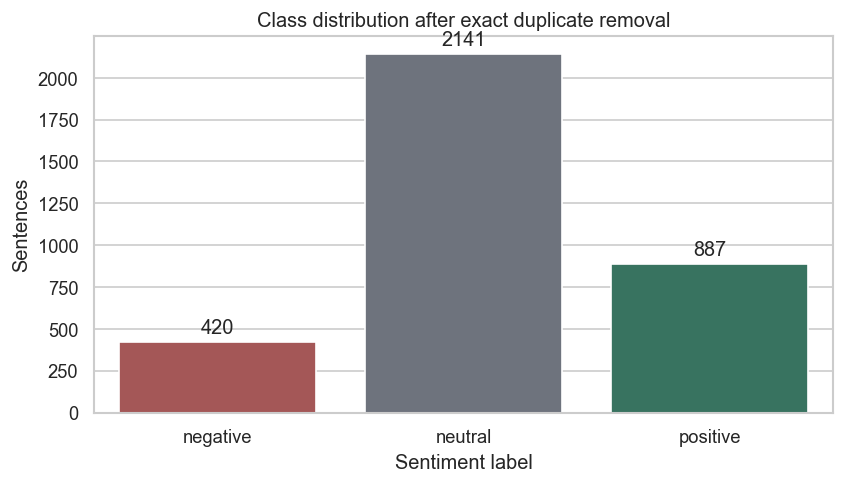

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
sns.barplot(data=class_summary.reset_index(), x="label", y="count", order=LABEL_ORDER, palette=["#B14A4A", "#6B7280", "#2E7D64"], hue="label", legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_title("Class distribution after exact duplicate removal")
ax.set_xlabel("Sentiment label")
ax.set_ylabel("Sentences")
plt.tight_layout()
plt.show()

The verified source contains 3,453 records. Five repeated neutral sentences are removed, leaving 3,448 unique sentences. There are no missing or blank values and no duplicated sentence has conflicting labels. Neutral sentences form the majority class, so macro-averaged evaluation is necessary alongside accuracy.

## Sentence length analysis

Word and character counts describe the input scale and inform the later BERT sequence-length choice.

In [6]:
clean_df = clean_df.assign(
    word_count=clean_df["sentence"].str.split().str.len(),
    character_count=clean_df["sentence"].str.len(),
)

length_summary = clean_df.groupby("label")[["word_count", "character_count"]].agg(["count", "mean", "median", "min", "max"])
length_summary.round(2)

word_count                       character_count                     \
              count   mean median min max           count    mean median min   
label                                                                          
negative        420  24.47   22.0   5  56             420  126.39  116.5  37   
neutral        2141  21.53   20.0   2  81            2141  120.85  111.0   9   
positive        887  24.88   23.0   6  57             887  133.64  126.0  26   

               
          max  
label          
negative  296  
neutral   315  
positive  298

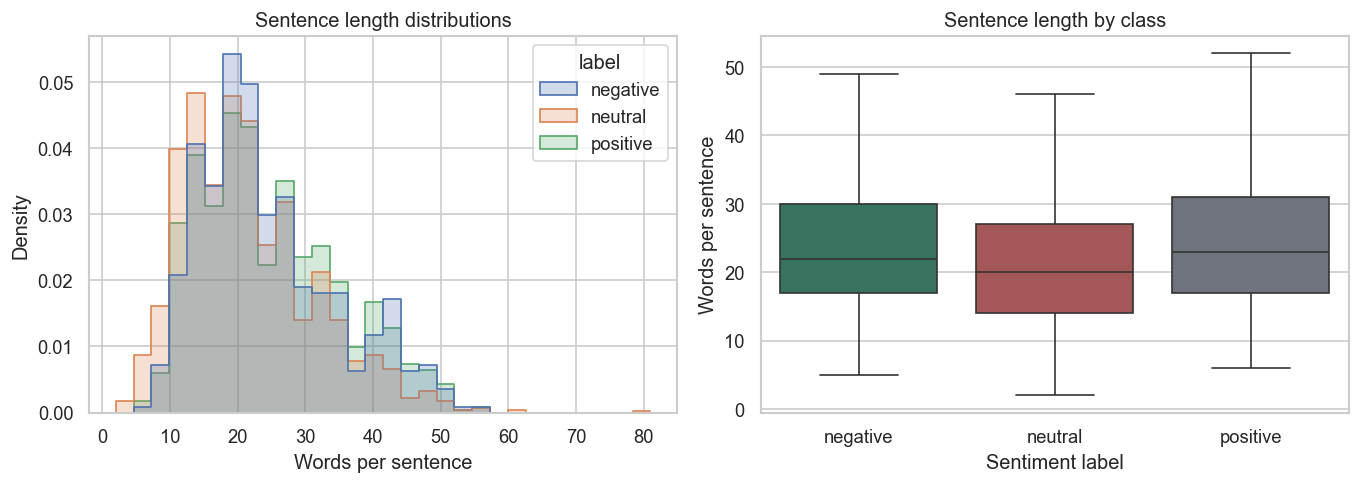

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
sns.histplot(data=clean_df, x="word_count", hue="label", hue_order=LABEL_ORDER, bins=30, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Sentence length distributions")
axes[0].set_xlabel("Words per sentence")
axes[0].set_ylabel("Density")
sns.boxplot(data=clean_df, x="label", y="word_count", order=LABEL_ORDER, palette=["#B14A4A", "#6B7280", "#2E7D64"], hue="label", legend=False, showfliers=False, ax=axes[1])
axes[1].set_title("Sentence length by class")
axes[1].set_xlabel("Sentiment label")
axes[1].set_ylabel("Words per sentence")
plt.tight_layout()
plt.show()

In [8]:
length_quantiles = clean_df["word_count"].quantile([0.5, 0.9, 0.95, 0.99, 1.0]).rename("words").to_frame()
length_quantiles

,words
0.50,21.0
0.90,37.3
0.95,42.0
0.99,50.0
1.00,81.0


Most sentences are short relative to the planned 128-token BERT input. The later preprocessing pipeline will still measure WordPiece lengths before training and report any truncation rather than assuming whitespace words equal model tokens.

## Representative samples

In [9]:
representative_samples = (
    clean_df.groupby("label", group_keys=False)
    .apply(lambda group: group.sample(n=3, random_state=SEED), include_groups=False)
    .reset_index(drop=True)
)
representative_samples[["sentence", "word_count", "character_count"]]

,sentence,word_count,character_count
0,The situation of coated magazine printing pape...,13,74
1,Alma Media 's operating profit amounted to EUR...,20,95
2,Reported operating margin was a negative 5.9 % .,9,48
3,Initial estimated total value of the contract ...,15,81
4,Part of the reductions will be made through re...,11,69
5,The previous offer was 3.4 % of voting rights ...,15,69
6,Revenue grew 1 percent to euro742 .2 million U...,15,83
7,Luxembourg-registered investment fund Amber Tr...,30,201
8,The company is also featured in the Ethibel Pi...,27,163


The samples show why financial sentiment is domain-specific. Labels reflect the likely financial effect of the stated event, while factual announcements without an explicit favorable or unfavorable implication are commonly neutral.

## Class-level bigrams

Frequent two-word sequences provide an interpretable view of recurring language without fitting a predictive model.

In [10]:
bigram_rows = []
for label in LABEL_ORDER:
    vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words="english", min_df=2)
    matrix = vectorizer.fit_transform(clean_df.loc[clean_df["label"] == label, "sentence"])
    totals = matrix.sum(axis=0).A1
    terms = vectorizer.get_feature_names_out()
    top_indices = totals.argsort()[-10:][::-1]
    bigram_rows.extend({"label": label, "bigram": terms[index], "count": int(totals[index])} for index in top_indices)

bigram_df = pd.DataFrame(bigram_rows)
bigram_df

,label,bigram,count
0,negative,eur mn,96
1,negative,operating profit,51
2,negative,mn eur,49
3,negative,net sales,44
4,negative,corresponding period,40
5,negative,net profit,34
6,negative,profit eur,32
7,negative,mln euro,27
8,negative,totalled eur,25
9,negative,mn compared,24


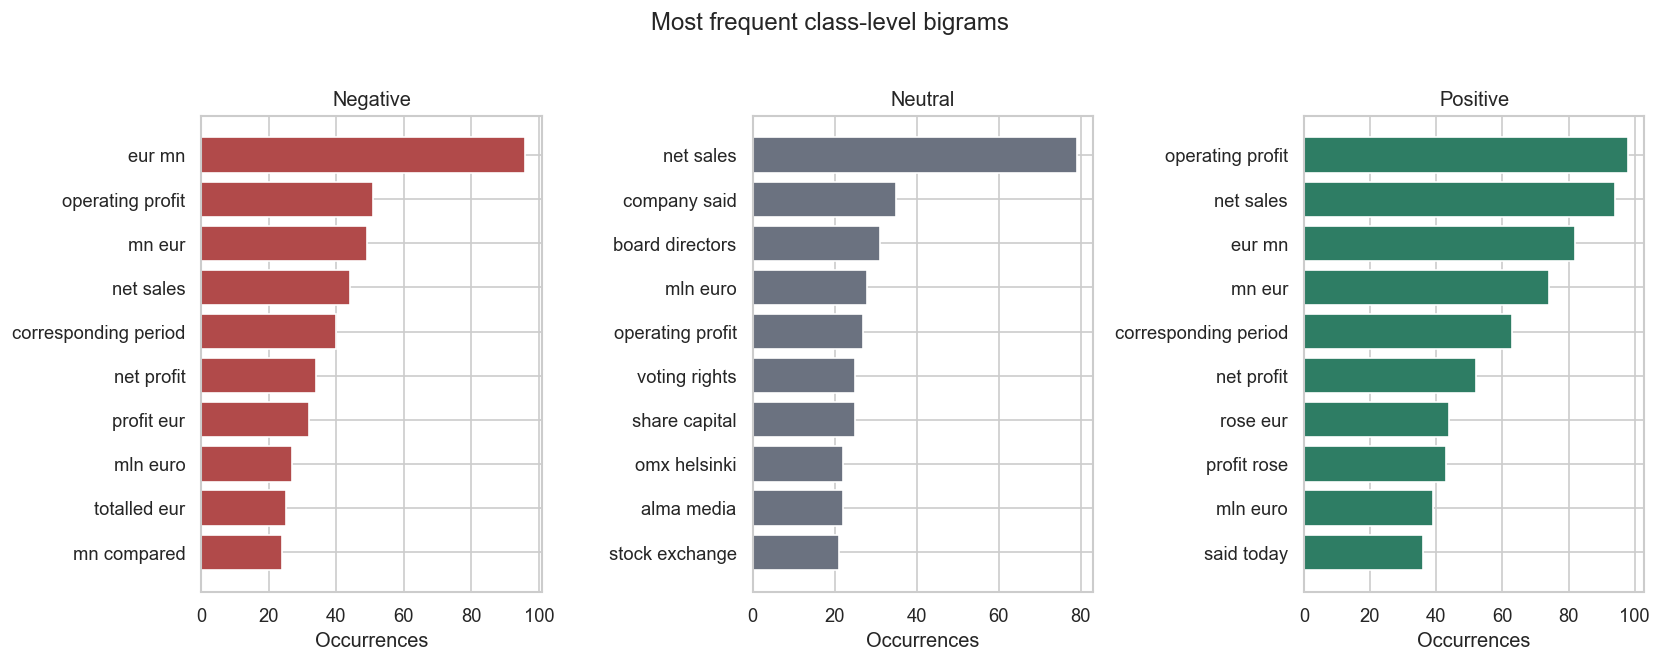

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), sharex=False)
colors = {"negative": "#B14A4A", "neutral": "#6B7280", "positive": "#2E7D64"}
for ax, label in zip(axes, LABEL_ORDER):
    subset = bigram_df[bigram_df["label"] == label].sort_values("count")
    ax.barh(subset["bigram"], subset["count"], color=colors[label])
    ax.set_title(label.capitalize())
    ax.set_xlabel("Occurrences")
    ax.set_ylabel("")
fig.suptitle("Most frequent class-level bigrams", y=1.02)
plt.tight_layout()
plt.show()

The bigrams reveal recurring company-report language and event terms. They are descriptive rather than causal, and frequent phrases may reflect source composition as much as sentiment. Later error analysis will check whether the classifier over-relies on company, currency, or reporting-period cues.

## Deterministic stratified partitions

The unique-sentence data is split into approximately 70 percent training, 15 percent validation, and 15 percent test data. The test split is selected first; the validation size is then fixed from the full dataset. All splits use seed 42 and preserve class proportions.

In [12]:
train_validation_df, test_df = train_test_split(
    clean_df,
    test_size=0.15,
    random_state=SEED,
    stratify=clean_df["label"],
)
validation_size = round(len(clean_df) * 0.15)
train_df, validation_df = train_test_split(
    train_validation_df,
    test_size=validation_size,
    random_state=SEED,
    stratify=train_validation_df["label"],
)

splits = {"train": train_df.reset_index(drop=True), "validation": validation_df.reset_index(drop=True), "test": test_df.reset_index(drop=True)}
split_sets = {name: set(frame["sentence"]) for name, frame in splits.items()}
assert not split_sets["train"] & split_sets["validation"]
assert not split_sets["train"] & split_sets["test"]
assert not split_sets["validation"] & split_sets["test"]
assert sum(len(frame) for frame in splits.values()) == len(clean_df)

split_summary = pd.concat(
    [
        frame["label"].value_counts().reindex(LABEL_ORDER).rename(name)
        for name, frame in splits.items()
    ],
    axis=1,
).T
split_summary["total"] = split_summary.sum(axis=1)
split_summary["share_percent"] = (split_summary["total"] / len(clean_df) * 100).round(2)
split_summary

label,negative,neutral,positive,total,share_percent
train,294,1498,621,2413,69.98
validation,63,321,133,517,14.99
test,63,322,133,518,15.02


In [13]:
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)
for name, frame in splits.items():
    frame[["sentence", "label"]].to_csv(processed_dir / f"{name}.csv", index=False)

overlap_summary = pd.DataFrame(
    {
        "comparison": ["train vs validation", "train vs test", "validation vs test"],
        "shared_sentences": [
            len(split_sets["train"] & split_sets["validation"]),
            len(split_sets["train"] & split_sets["test"]),
            len(split_sets["validation"] & split_sets["test"]),
        ],
    }
)
overlap_summary

,comparison,shared_sentences
0,train vs validation,0
1,train vs test,0
2,validation vs test,0


All 3,448 unique sentences are assigned once. The saved partitions are disjoint and retain the source class imbalance. The test data must remain untouched until final model selection is complete.

## Milestone conclusion

The verified `sentences_75agree` source has 3,453 rows with 2,146 neutral, 887 positive, and 420 negative labels. Removing five exact neutral duplicates produces 3,448 unique records. The deterministic split creates 2,413 training, 517 validation, and 518 test records with zero shared sentences. These results establish the data basis for the later TF-IDF logistic-regression baseline and BERT fine-tuning; neither model is trained in this Week 8 notebook.